# Loan Approval Prediction using a CART Decision Tree

This notebook applies the same CART workflow to a **different dataset**: a small loan-approval table.
Each applicant is described by income level, credit score band, employment type and whether they offer collateral. The target is whether the loan was **Approved**.

Workflow:
1. Build and inspect the dataset
2. Visualise the target and features
3. Compute Gini impurity by hand to find the best first split
4. Build a preprocessing + CART pipeline
5. Evaluate (hold-out test and cross-validation)
6. Visualise and print the tree rules
7. Check feature importance
8. Predict new applicants

The data is small and illustrative, so treat this as a learning example, not a real credit model.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

SEED = 7
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100

## 2. Create the loan dataset

In [2]:
COLUMNS = ["Income", "CreditScore", "Employment", "Collateral", "Approved"]

records = [
    ("High",   "Good", "Salaried",     "Yes", "Yes"),
    ("High",   "Good", "SelfEmployed", "No",  "Yes"),
    ("High",   "Fair", "Salaried",     "No",  "Yes"),
    ("High",   "Fair", "SelfEmployed", "No",  "No"),
    ("High",   "Poor", "Salaried",     "Yes", "Yes"),
    ("High",   "Poor", "Unemployed",   "No",  "No"),
    ("Medium", "Good", "Salaried",     "No",  "Yes"),
    ("Medium", "Good", "SelfEmployed", "Yes", "Yes"),
    ("Medium", "Good", "Unemployed",   "No",  "No"),
    ("Medium", "Fair", "Salaried",     "Yes", "Yes"),
    ("Medium", "Fair", "Salaried",     "No",  "No"),
    ("Medium", "Fair", "SelfEmployed", "No",  "No"),
    ("Medium", "Poor", "Salaried",     "No",  "No"),
    ("Medium", "Poor", "SelfEmployed", "Yes", "No"),
    ("Low",    "Good", "Salaried",     "Yes", "Yes"),
    ("Low",    "Good", "Salaried",     "No",  "No"),
    ("Low",    "Fair", "Salaried",     "No",  "No"),
    ("Low",    "Fair", "Unemployed",   "Yes", "No"),
    ("Low",    "Poor", "SelfEmployed", "No",  "No"),
    ("Low",    "Poor", "Unemployed",   "No",  "No"),
    ("Low",    "Good", "SelfEmployed", "Yes", "Yes"),
    ("High",   "Good", "Unemployed",   "Yes", "Yes"),
]

loans = pd.DataFrame.from_records(records, columns=COLUMNS)
TARGET = "Approved"
FEATURES = [c for c in loans.columns if c != TARGET]

loans.head(8)

,Income,CreditScore,Employment,Collateral,Approved
0,High,Good,Salaried,Yes,Yes
1,High,Good,SelfEmployed,No,Yes
2,High,Fair,Salaried,No,Yes
3,High,Fair,SelfEmployed,No,No
4,High,Poor,Salaried,Yes,Yes
5,High,Poor,Unemployed,No,No
6,Medium,Good,Salaried,No,Yes
7,Medium,Good,SelfEmployed,Yes,Yes


In [3]:
summary = pd.DataFrame({
    "unique_values": loans.nunique(),
    "missing": loans.isna().sum(),
})
print(f"Shape: {loans.shape}")
display(summary)
display(loans[TARGET].value_counts().to_frame("count"))

Shape: (22, 5)


,unique_values,missing
Income,3,0
CreditScore,3,0
Employment,3,0
Collateral,2,0
Approved,2,0


,count
Approved,
No,12
Yes,10


## 3. Explore the data

The chart below shows the approval rate for every value of every feature, which gives an early hint about which columns matter.

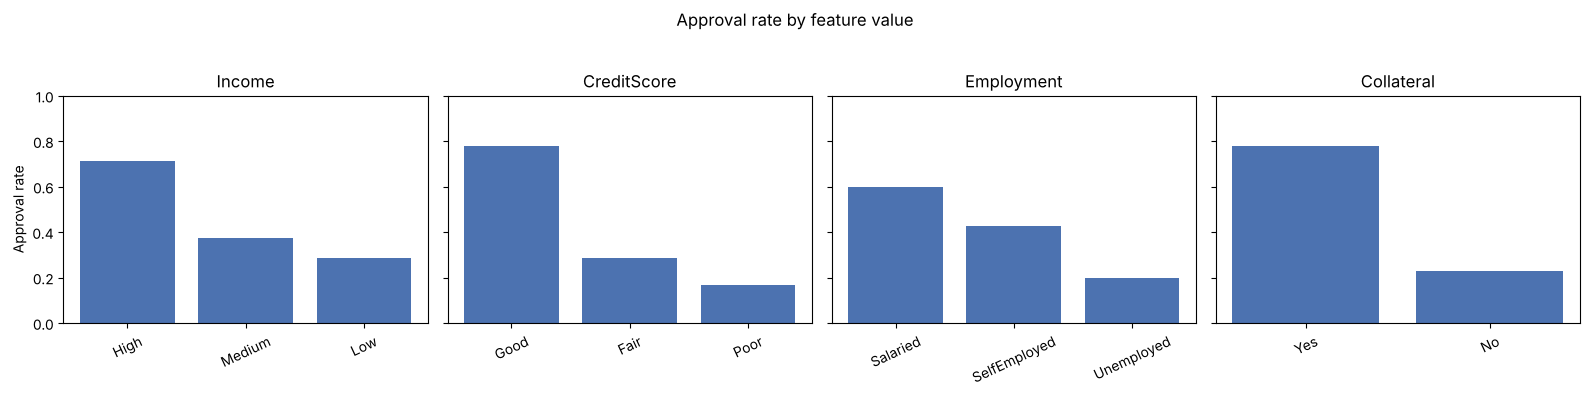

In [4]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(16, 3.8), sharey=True)

for ax, feat in zip(axes, FEATURES):
    rate = (loans[TARGET].eq("Yes")
            .groupby(loans[feat]).mean()
            .sort_values(ascending=False))
    ax.bar(rate.index, rate.values, color="#4c72b0")
    ax.set_title(feat)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

axes[0].set_ylabel("Approval rate")
fig.suptitle("Approval rate by feature value", y=1.03)
plt.tight_layout()
plt.show()

## 4. Gini impurity by hand

For a group with class proportions $p_i$:

$$Gini = 1 - \sum_i p_i^2$$

A pure group has Gini 0. For each candidate rule (`feature == value`), we compute the weighted Gini of the two child groups and the reduction compared with the parent.

In [5]:
def gini_impurity(labels: pd.Series) -> float:
    if len(labels) == 0:
        return 0.0
    p = labels.value_counts(normalize=True).to_numpy()
    return float(1.0 - np.sum(p ** 2))


def evaluate_splits(frame: pd.DataFrame) -> pd.DataFrame:
    parent = gini_impurity(frame[TARGET])
    n = len(frame)
    rows = []
    for feat in FEATURES:
        for val in frame[feat].unique():
            mask = frame[feat] == val
            yes_side, no_side = frame[mask][TARGET], frame[~mask][TARGET]
            weighted = (len(yes_side) * gini_impurity(yes_side)
                        + len(no_side) * gini_impurity(no_side)) / n
            rows.append({
                "Rule": f"{feat} == {val}",
                "Rows matching": len(yes_side),
                "Gini (match)": gini_impurity(yes_side),
                "Gini (other)": gini_impurity(no_side),
                "Weighted Gini": weighted,
                "Gain": parent - weighted,
            })
    return pd.DataFrame(rows).sort_values("Gain", ascending=False, ignore_index=True)


print(f"Parent Gini: {gini_impurity(loans[TARGET]):.4f}")
split_table = evaluate_splits(loans)
display(split_table.round(4).head(8))
print("Best first split:", split_table.loc[0, "Rule"])

Parent Gini: 0.4959


,Rule,Rows matching,Gini (match),Gini (other),Weighted Gini,Gain
0,Collateral == Yes,9,0.3457,0.3550,0.3512,0.1447
1,Collateral == No,13,0.3550,0.3457,0.3512,0.1447
2,CreditScore == Good,9,0.3457,0.3550,0.3512,0.1447
3,Income == High,7,0.4082,0.4444,0.4329,0.0630
4,CreditScore == Poor,6,0.2778,0.4922,0.4337,0.0622
5,Employment == Unemployed,5,0.3200,0.4983,0.4578,0.0381
6,Employment == Salaried,10,0.4800,0.4444,0.4606,0.0353
7,CreditScore == Fair,7,0.4082,0.4978,0.4693,0.0266


Best first split: Collateral == Yes


## 5. Train/test split and the CART pipeline

The encoder and the tree are wrapped in a single `Pipeline`, so the encoder is fitted only on training data and the same steps are applied automatically to new data.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    loans[FEATURES], loans[TARGET],
    test_size=0.25, stratify=loans[TARGET], random_state=SEED,
)

cart_pipeline = Pipeline(steps=[
    ("encode", ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore"), FEATURES)]
    )),
    ("tree", DecisionTreeClassifier(
        criterion="gini", max_depth=4, min_samples_leaf=1, random_state=SEED,
    )),
])

cart_pipeline.fit(X_train, y_train)
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Tree depth: {cart_pipeline['tree'].get_depth()}, leaves: {cart_pipeline['tree'].get_n_leaves()}")

Train rows: 16 | Test rows: 6
Tree depth: 4, leaves: 7


## 6. Evaluation

With so few rows, a single split is noisy. We therefore also run stratified 5-fold cross-validation.

In [7]:
y_hat = cart_pipeline.predict(X_test)
print(f"Hold-out accuracy: {accuracy_score(y_test, y_hat):.2%}\n")
print(classification_report(y_test, y_hat, zero_division=0))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(cart_pipeline, loans[FEATURES], loans[TARGET], cv=cv)
print("Cross-validation accuracy per fold:", np.round(cv_scores, 3))
print(f"Mean CV accuracy: {cv_scores.mean():.2%} (+/- {cv_scores.std():.2%})")

Hold-out accuracy: 66.67%

              precision    recall  f1-score   support

          No       1.00      0.33      0.50         3
         Yes       0.60      1.00      0.75         3

    accuracy                           0.67         6
   macro avg       0.80      0.67      0.62         6
weighted avg       0.80      0.67      0.62         6

Cross-validation accuracy per fold: [0.6  0.8  0.25 0.75 1.  ]
Mean CV accuracy: 68.00% (+/- 25.02%)


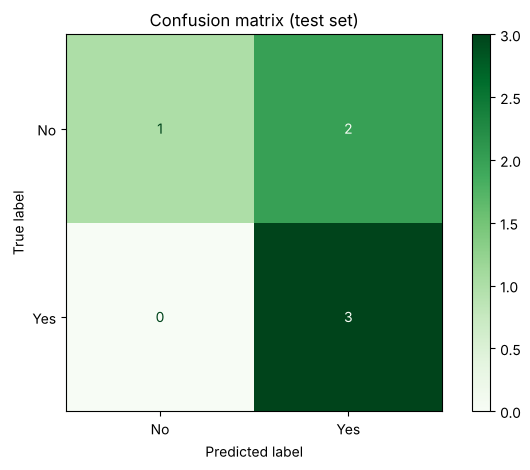

In [8]:
ConfusionMatrixDisplay.from_estimator(
    cart_pipeline, X_test, y_test, labels=["No", "Yes"], cmap="Greens"
)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

## 7. The learned tree

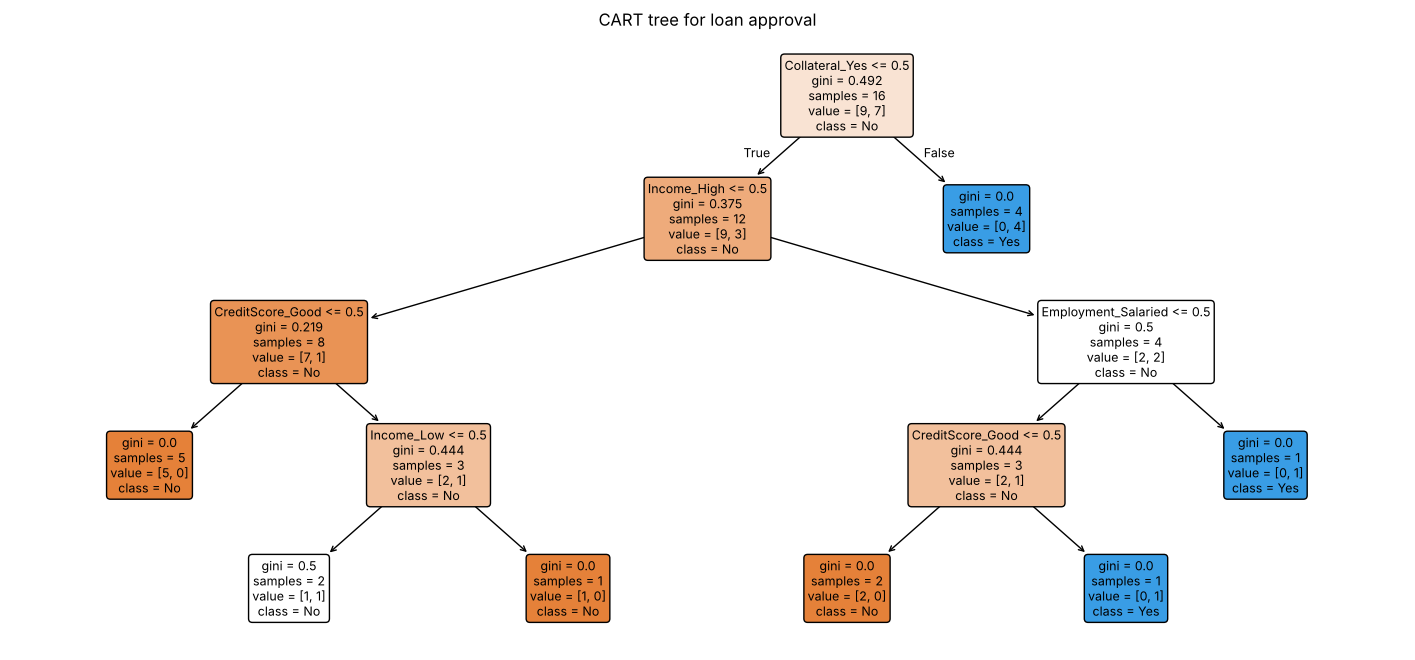

In [9]:
encoder = cart_pipeline["encode"]
tree = cart_pipeline["tree"]
feat_names = [n.replace("onehot__", "") for n in encoder.get_feature_names_out()]

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=feat_names, class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=9)
plt.title("CART tree for loan approval")
plt.show()

In [10]:
print(export_text(tree, feature_names=feat_names))

|--- Collateral_Yes <= 0.50
|   |--- Income_High <= 0.50
|   |   |--- CreditScore_Good <= 0.50
|   |   |   |--- class: No
|   |   |--- CreditScore_Good >  0.50
|   |   |   |--- Income_Low <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Income_Low >  0.50
|   |   |   |   |--- class: No
|   |--- Income_High >  0.50
|   |   |--- Employment_Salaried <= 0.50
|   |   |   |--- CreditScore_Good <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- CreditScore_Good >  0.50
|   |   |   |   |--- class: Yes
|   |   |--- Employment_Salaried >  0.50
|   |   |   |--- class: Yes
|--- Collateral_Yes >  0.50
|   |--- class: Yes



## 8. Feature importance

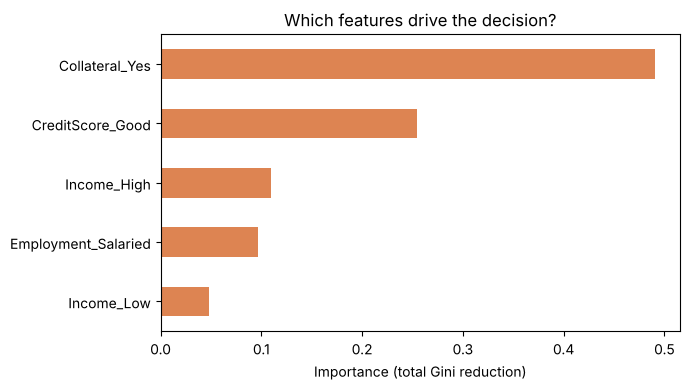

In [11]:
importance = (pd.Series(tree.feature_importances_, index=feat_names)
              .sort_values(ascending=True))
importance = importance[importance > 0]

importance.plot(kind="barh", figsize=(7, 4), color="#dd8452")
plt.xlabel("Importance (total Gini reduction)")
plt.title("Which features drive the decision?")
plt.tight_layout()
plt.show()

## 9. Predict new applicants

In [12]:
applicants = pd.DataFrame([
    {"Income": "High",   "CreditScore": "Good", "Employment": "Salaried",     "Collateral": "No"},
    {"Income": "Low",    "CreditScore": "Poor", "Employment": "Unemployed",   "Collateral": "No"},
    {"Income": "Medium", "CreditScore": "Fair", "Employment": "SelfEmployed", "Collateral": "Yes"},
    {"Income": "Low",    "CreditScore": "Good", "Employment": "Salaried",     "Collateral": "Yes"},
])

proba = cart_pipeline.predict_proba(applicants)
result = applicants.assign(
    Decision=cart_pipeline.predict(applicants),
    Confidence=[f"{p:.0%}" for p in proba.max(axis=1)],
)
result

,Income,CreditScore,Employment,Collateral,Decision,Confidence
0,High,Good,Salaried,No,Yes,100%
1,Low,Poor,Unemployed,No,No,100%
2,Medium,Fair,SelfEmployed,Yes,Yes,100%
3,Low,Good,Salaried,Yes,Yes,100%


## 10. Summary

- The workflow is the same as in the PlayTennis notebook, applied to loan approval.
- Collateral gave the best first split, followed by income and credit score.
- A `Pipeline` keeps preprocessing and model together and avoids data leakage.
- Accuracy varies a lot between folds (small data), so cross-validation is more honest than one test split.
- More data would be needed before using such a model for real decisions.